# Customer Churn Analysis using Apache Spark (PySpark)
**Aim:** Analyse customer data with PySpark to find why customers churn, build Spark MLlib models that
predict churn, and serve the model through a Streamlit web application.

**Tools:** PySpark (DataFrame API, Spark SQL, MLlib) · Streamlit · Google Colab

**Dataset:** `customer_churn_dataset-testing-master.csv` — 64,374 customers, 12 columns.

> Run the cells from top to bottom (**Runtime → Run all** also works; the upload cell will wait for the file).

## 1. Install libraries and check Java
PySpark runs on the JVM, so Java must be present. Colab usually has it; if not, this cell installs it.

In [ ]:
!pip install -q pyspark==3.5.3 streamlit

import shutil, subprocess
if shutil.which("java") is None:
    print("Java not found, installing OpenJDK 17 ...")
    subprocess.run("apt-get install -y -qq openjdk-17-jdk-headless > /dev/null", shell=True)
!java -version

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.3/317.3 MB 4.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.5/200.5 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 53.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 50.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.3 which is incompatible.
[0.027s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.027s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.

## 2. Upload the dataset
Run the cell and choose `customer_churn_dataset-testing-master.csv` from your computer.

In [ ]:
import os
if not os.path.exists("customer_churn.csv"):
    from google.colab import files
    uploaded = files.upload()
    os.rename(list(uploaded)[0], "customer_churn.csv")
print("Dataset ready:", os.path.getsize("customer_churn.csv") // 1024, "KB")

Saving customer_churn_dataset-testing-master.csv to customer_churn_dataset-testing-master.csv
Dataset ready: 3205 KB


## 3. Create the Spark session

In [ ]:
import warnings
warnings.filterwarnings("ignore")

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("CustomerChurnAnalysis")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)

Spark version: 3.5.3


## 4. Load the data into a Spark DataFrame

In [ ]:
raw = spark.read.csv("customer_churn.csv", header=True, inferSchema=True)
raw.printSchema()
raw.show(5)
print("Rows:", raw.count(), "| Columns:", len(raw.columns))

root
 |-- CustomerID: integer (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Tenure: integer (nullable = true)
 |-- Usage Frequency: integer (nullable = true)
 |-- Support Calls: integer (nullable = true)
 |-- Payment Delay: integer (nullable = true)
 |-- Subscription Type: string (nullable = true)
 |-- Contract Length: string (nullable = true)
 |-- Total Spend: integer (nullable = true)
 |-- Last Interaction: integer (nullable = true)
 |-- Churn: integer (nullable = true)

+----------+---+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----+
|CustomerID|Age|Gender|Tenure|Usage Frequency|Support Calls|Payment Delay|Subscription Type|Contract Length|Total Spend|Last Interaction|Churn|
+----------+---+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----+
|         1| 22|Female|    25|         

## 5. Data cleaning
Rename columns to snake_case, check nulls, drop duplicates and missing rows.

In [ ]:
RENAME = {"CustomerID": "customer_id", "Age": "age", "Gender": "gender", "Tenure": "tenure",
          "Usage Frequency": "usage_frequency", "Support Calls": "support_calls",
          "Payment Delay": "payment_delay", "Subscription Type": "subscription_type",
          "Contract Length": "contract_length", "Total Spend": "total_spend",
          "Last Interaction": "last_interaction", "Churn": "churn"}
df = raw
for old, new in RENAME.items():
    df = df.withColumnRenamed(old, new)

print("Null values per column:")
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).show()

before = df.count()
df = df.dropDuplicates(["customer_id"]).dropna()
print(f"Rows before: {before:,} | after cleaning: {df.count():,}")

NUMERIC = ["age", "tenure", "usage_frequency", "support_calls", "payment_delay", "total_spend", "last_interaction"]
CATEGORICAL = ["gender", "subscription_type", "contract_length"]
df.select(NUMERIC).summary("mean", "stddev", "min", "50%", "max").show()

Null values per column:
+-----------+---+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----+
|customer_id|age|gender|tenure|usage_frequency|support_calls|payment_delay|subscription_type|contract_length|total_spend|last_interaction|churn|
+-----------+---+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----+
|          0|  0|     0|     0|              0|            0|            0|                0|              0|          0|               0|    0|
+-----------+---+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----+

Rows before: 64,374 | after cleaning: 64,374
+-------+------------------+------------------+------------------+-----------------+-----------------+------------------+------------------+
|summary|               age|            tenure|   usage_frequenc

## 6. Feature engineering
- `spend_per_month` = total spend / tenure
- `calls_per_usage` = support calls per unit of usage
- `age_group`, `tenure_group` = buckets for analysis

In [ ]:
def add_features(d):
    return (d
        .withColumn("spend_per_month", F.round(F.col("total_spend") / F.greatest(F.col("tenure"), F.lit(1)), 2))
        .withColumn("calls_per_usage", F.round(F.col("support_calls") / (F.col("usage_frequency") + 1), 3))
        .withColumn("age_group", F.when(F.col("age") < 30, "18-29").when(F.col("age") < 45, "30-44")
                                  .when(F.col("age") < 60, "45-59").otherwise("60+"))
        .withColumn("tenure_group", F.when(F.col("tenure") <= 12, "0-12 m").when(F.col("tenure") <= 24, "13-24 m")
                                     .when(F.col("tenure") <= 36, "25-36 m").otherwise("37+ m")))

df = add_features(df).cache()
df.createOrReplaceTempView("customers")
df.select("customer_id", "tenure", "total_spend", "spend_per_month", "calls_per_usage", "age_group", "tenure_group").show(5)

+-----------+------+-----------+---------------+---------------+---------+------------+
|customer_id|tenure|total_spend|spend_per_month|calls_per_usage|age_group|tenure_group|
+-----------+------+-----------+---------------+---------------+---------+------------+
|         12|    13|        187|          14.38|          0.208|    45-59|     13-24 m|
|         13|     2|        758|          379.0|            0.0|    30-44|      0-12 m|
|         14|    46|        438|           9.52|          0.179|    30-44|       37+ m|
|         18|     9|        127|          14.11|          0.129|    45-59|      0-12 m|
|         38|    27|        384|          14.22|            0.5|    45-59|     25-36 m|
+-----------+------+-----------+---------------+---------------+---------+------------+
only showing top 5 rows



## 7. Exploratory Data Analysis (Spark DataFrame API)
### 7.1 Churn distribution

+-----+-----+-------+
|churn|count|percent|
+-----+-----+-------+
|    0|33881|  52.63|
|    1|30493|  47.37|
+-----+-----+-------+



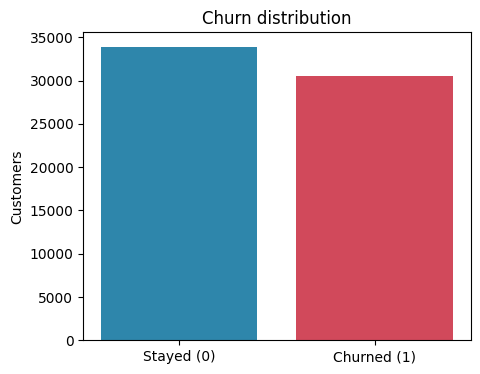

In [ ]:
import matplotlib.pyplot as plt

dist = df.groupBy("churn").count().orderBy("churn")
dist.withColumn("percent", F.round(F.col("count") * 100 / df.count(), 2)).show()

p = dist.toPandas()
plt.figure(figsize=(5, 4))
plt.bar(["Stayed (0)", "Churned (1)"], p["count"], color=["#2e86ab", "#d1495b"])
plt.title("Churn distribution"); plt.ylabel("Customers")
plt.show()

### 7.2 Churn rate by category

+------+---------+----------+
|gender|customers|churn_rate|
+------+---------+----------+
|Female|    34353|     55.05|
|  Male|    30021|     38.58|
+------+---------+----------+

+-----------------+---------+----------+
|subscription_type|customers|churn_rate|
+-----------------+---------+----------+
|            Basic|    21451|     48.28|
|          Premium|    21421|      46.5|
|         Standard|    21502|     47.33|
+-----------------+---------+----------+

+---------------+---------+----------+
|contract_length|customers|churn_rate|
+---------------+---------+----------+
|         Annual|    21410|     46.22|
|        Monthly|    22130|     51.61|
|      Quarterly|    20834|     44.05|
+---------------+---------+----------+

+---------+---------+----------+
|age_group|customers|churn_rate|
+---------+---------+----------+
|    18-29|    15547|     44.49|
|    30-44|    19700|     44.69|
|    45-59|    20572|     50.01|
|      60+|     8555|     52.43|
+---------+---------+-----

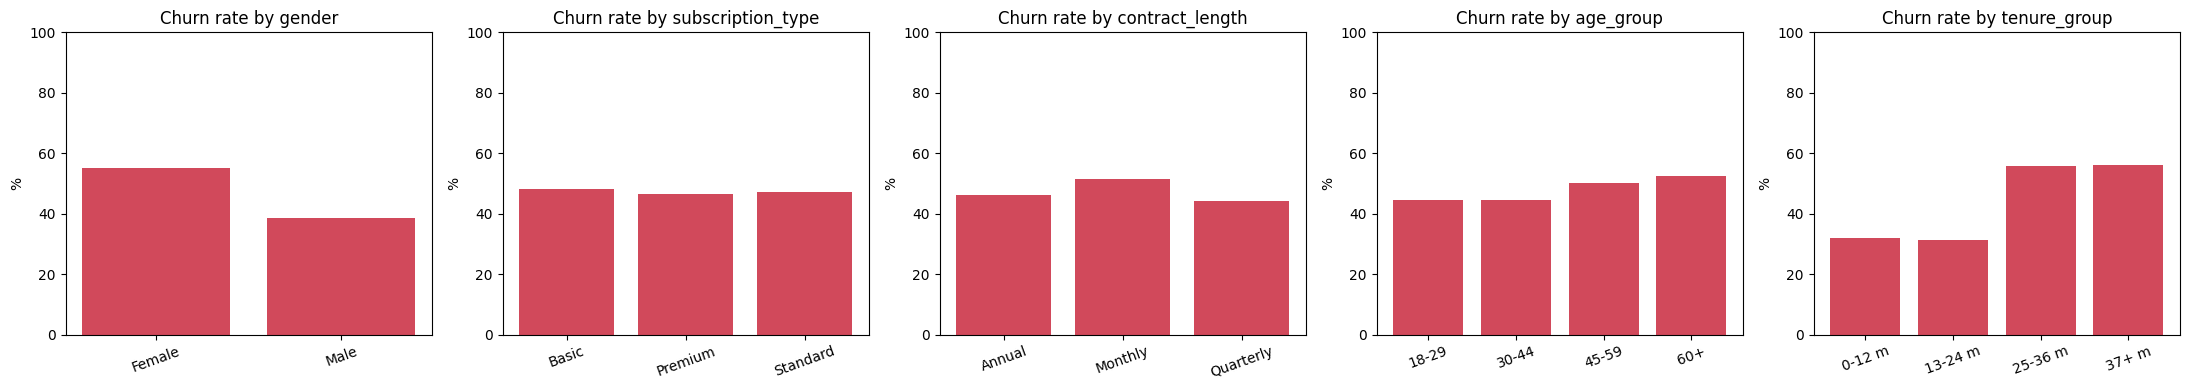

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, c in zip(axes, ["gender", "subscription_type", "contract_length", "age_group", "tenure_group"]):
    t = (df.groupBy(c).agg(F.count("*").alias("customers"), F.round(F.avg("churn") * 100, 2).alias("churn_rate"))
           .orderBy(c))
    t.show()
    t = t.toPandas()
    ax.bar(t[c], t["churn_rate"], color="#d1495b")
    ax.set_title(f"Churn rate by {c}"); ax.set_ylim(0, 100); ax.set_ylabel("%")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

### 7.3 Churned vs stayed: average of each numeric feature

In [ ]:
df.groupBy("churn").agg(*[F.round(F.avg(c), 2).alias(c) for c in NUMERIC]).orderBy("churn").show()

+-----+-----+------+---------------+-------------+-------------+-----------+----------------+
|churn|  age|tenure|usage_frequency|support_calls|payment_delay|total_spend|last_interaction|
+-----+-----+------+---------------+-------------+-------------+-----------+----------------+
|    0|41.13| 28.83|          16.04|          4.5|        12.45|     560.54|           15.52|
|    1| 42.9| 35.52|          14.01|          6.4|        22.33|     519.34|           15.47|
+-----+-----+------+---------------+-------------+-------------+-----------+----------------+



### 7.4 Correlation with churn (Spark ML `Correlation`)

payment_delay       0.557
support_calls       0.305
tenure              0.195
usage_frequency    -0.115
total_spend        -0.079
age                 0.063
last_interaction   -0.003
Name: churn, dtype: float64


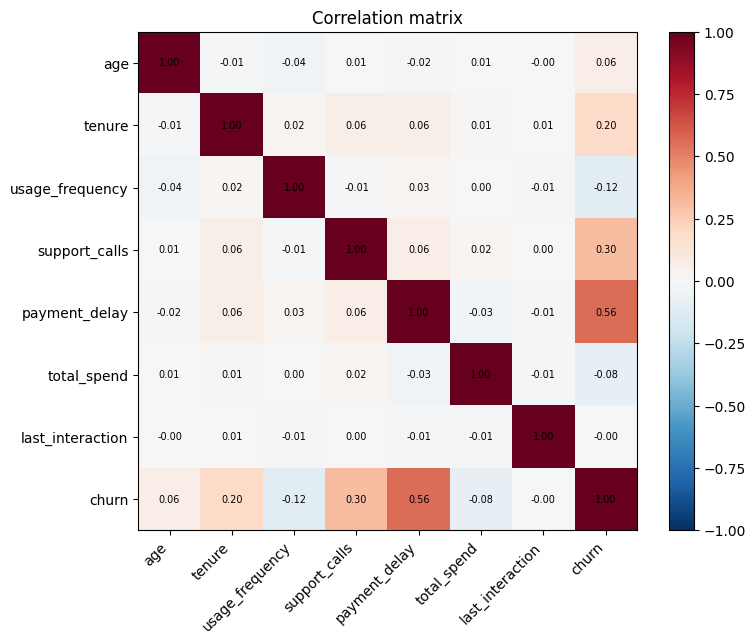

In [ ]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
import pandas as pd

cols = NUMERIC + ["churn"]
vec = VectorAssembler(inputCols=cols, outputCol="v").transform(df).select("v")
corr = pd.DataFrame(Correlation.corr(vec, "v").head()[0].toArray(), index=cols, columns=cols).round(3)
print(corr["churn"].drop("churn").sort_values(key=abs, ascending=False))

plt.figure(figsize=(8, 6.5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(cols)), cols, rotation=45, ha="right"); plt.yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

## 8. Business insights with Spark SQL

Churn by subscription x contract
+-----------------+---------------+---------+--------------+
|subscription_type|contract_length|customers|churn_rate_pct|
+-----------------+---------------+---------+--------------+
|            Basic|        Monthly|     7373|         52.11|
|         Standard|        Monthly|     7348|         51.85|
|          Premium|        Monthly|     7409|         50.87|
|            Basic|         Annual|     7148|         47.13|
|         Standard|         Annual|     7187|         45.87|
|          Premium|         Annual|     7075|         45.64|
|            Basic|      Quarterly|     6930|         45.38|
|         Standard|      Quarterly|     6967|         44.06|
|          Premium|      Quarterly|     6937|          42.7|
+-----------------+---------------+---------+--------------+

Churn by payment delay
+------------+---------+--------------+
|delay_bucket|customers|churn_rate_pct|
+------------+---------+--------------+
|   0-10 days|    17182|      

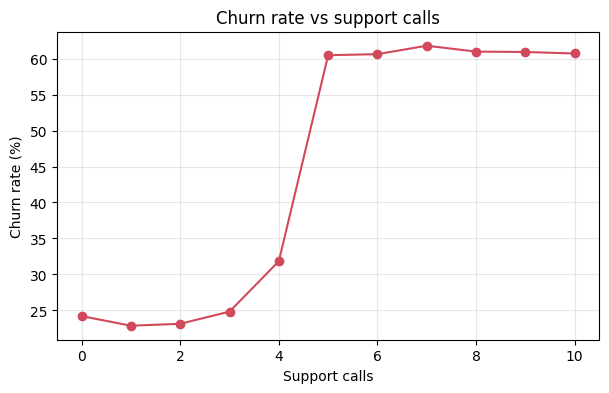

In [ ]:
print("Churn by subscription x contract")
spark.sql("""
    SELECT subscription_type, contract_length, COUNT(*) AS customers,
           ROUND(AVG(churn) * 100, 2) AS churn_rate_pct
    FROM customers GROUP BY subscription_type, contract_length ORDER BY churn_rate_pct DESC
""").show()

print("Churn by payment delay")
spark.sql("""
    SELECT CASE WHEN payment_delay <= 10 THEN '0-10 days' WHEN payment_delay <= 20 THEN '11-20 days'
                ELSE '21+ days' END AS delay_bucket,
           COUNT(*) AS customers, ROUND(AVG(churn) * 100, 2) AS churn_rate_pct
    FROM customers GROUP BY 1 ORDER BY 1
""").show()

print("Revenue lost to churn")
spark.sql("""
    SELECT subscription_type,
           SUM(CASE WHEN churn = 1 THEN total_spend ELSE 0 END) AS revenue_lost,
           SUM(total_spend) AS total_revenue
    FROM customers GROUP BY subscription_type ORDER BY revenue_lost DESC
""").show()

print("High-risk segment: support_calls > 5 AND payment_delay > 20")
spark.sql("""
    SELECT COUNT(*) AS customers, ROUND(AVG(churn) * 100, 2) AS churn_rate_pct
    FROM customers WHERE support_calls > 5 AND payment_delay > 20
""").show()

sc = spark.sql("SELECT support_calls, ROUND(AVG(churn)*100, 2) AS rate FROM customers GROUP BY 1 ORDER BY 1").toPandas()
plt.figure(figsize=(7, 4)); plt.plot(sc.support_calls, sc.rate, marker="o", color="#d1495b")
plt.title("Churn rate vs support calls"); plt.xlabel("Support calls"); plt.ylabel("Churn rate (%)"); plt.grid(alpha=.3)
plt.show()

## 9. Machine learning with Spark MLlib
### 9.1 Train / test split (stratified 80:20) and preprocessing pipeline
`StringIndexer → OneHotEncoder → VectorAssembler → StandardScaler → Classifier`

In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, StandardScaler

train = df.sampleBy("churn", fractions={0: 0.8, 1: 0.8}, seed=42).cache()
test = df.join(train.select("customer_id"), "customer_id", "left_anti").cache()
print(f"Train: {train.count():,} | Test: {test.count():,}")

FEATURES = NUMERIC + ["spend_per_month", "calls_per_usage"]

def prep_stages():
    idx = [StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in CATEGORICAL]
    ohe = OneHotEncoder(inputCols=[c + "_idx" for c in CATEGORICAL], outputCols=[c + "_ohe" for c in CATEGORICAL])
    asm = VectorAssembler(inputCols=FEATURES + [c + "_ohe" for c in CATEGORICAL], outputCol="raw_features")
    sc = StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)
    return idx + [ohe, asm, sc]

Train: 51,742 | Test: 12,632


### 9.2 Train and evaluate four classifiers

In [ ]:
from pyspark.ml.classification import (LogisticRegression, DecisionTreeClassifier,
                                       RandomForestClassifier, GBTClassifier)
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

def evaluate(pred, name):
    auc = BinaryClassificationEvaluator(labelCol="churn").evaluate(pred)
    m = lambda k: MulticlassClassificationEvaluator(labelCol="churn", metricName=k).evaluate(pred)
    cm = {(r["churn"], int(r["prediction"])): r["count"] for r in pred.groupBy("churn", "prediction").count().collect()}
    tp, fp, fn, tn = cm.get((1, 1), 0), cm.get((0, 1), 0), cm.get((1, 0), 0), cm.get((0, 0), 0)
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    return {"model": name, "accuracy": round(m("accuracy"), 4), "precision": round(prec, 4),
            "recall": round(rec, 4), "f1": round(2 * prec * rec / (prec + rec), 4), "roc_auc": round(auc, 4),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

models = {
    "Logistic Regression": LogisticRegression(labelCol="churn", maxIter=100),
    "Decision Tree": DecisionTreeClassifier(labelCol="churn", maxDepth=6, seed=42),
    "Random Forest": RandomForestClassifier(labelCol="churn", numTrees=100, maxDepth=8, seed=42),
    "Gradient Boosted Trees": GBTClassifier(labelCol="churn", maxIter=50, maxDepth=5, seed=42),
}
results = []
for name, clf in models.items():
    fitted = Pipeline(stages=prep_stages() + [clf]).fit(train)
    r = evaluate(fitted.transform(test), name)
    results.append(r)
    print(f"{name:<24} accuracy={r['accuracy']}  f1={r['f1']}  auc={r['roc_auc']}")

Logistic Regression      accuracy=0.8376  f1=0.8309  auc=0.9084
Decision Tree            accuracy=0.9783  f1=0.9772  auc=0.9951
Random Forest            accuracy=0.9932  f1=0.9928  auc=0.9997
Gradient Boosted Trees   accuracy=0.993  f1=0.9926  auc=0.9997


### 9.3 Hyper-parameter tuning: Random Forest with 3-fold CrossValidator

In [ ]:
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

rf = RandomForestClassifier(labelCol="churn", seed=42)
grid = ParamGridBuilder().addGrid(rf.numTrees, [50, 100]).addGrid(rf.maxDepth, [6, 10]).build()
cv = CrossValidator(estimator=Pipeline(stages=prep_stages() + [rf]), estimatorParamMaps=grid,
                    evaluator=BinaryClassificationEvaluator(labelCol="churn"), numFolds=3, seed=42, parallelism=2)
best_model = cv.fit(train).bestModel
best_rf = best_model.stages[-1]
print("Best params -> numTrees:", best_rf.getNumTrees, "| maxDepth:", best_rf.getOrDefault("maxDepth"))

best_pred = best_model.transform(test)
results.append(evaluate(best_pred, "Random Forest (CV tuned)"))
comparison = pd.DataFrame(results)
comparison

Best params -> numTrees: 100 | maxDepth: 10


,model,accuracy,precision,recall,f1,roc_auc,TN,FP,FN,TP
0,Logistic Regression,0.8376,0.8227,0.8393,0.8309,0.9084,5542,1086,965,5039
1,Decision Tree,0.9783,0.9754,0.9790,0.9772,0.9951,6480,148,126,5878
2,Random Forest,0.9932,0.9940,0.9917,0.9928,0.9997,6592,36,50,5954
3,Gradient Boosted Trees,0.9930,0.9937,0.9915,0.9926,0.9997,6590,38,51,5953
4,Random Forest (CV tuned),0.9966,0.9962,0.9967,0.9964,0.9999,6605,23,20,5984


### 9.4 Model comparison, confusion matrix and feature importance

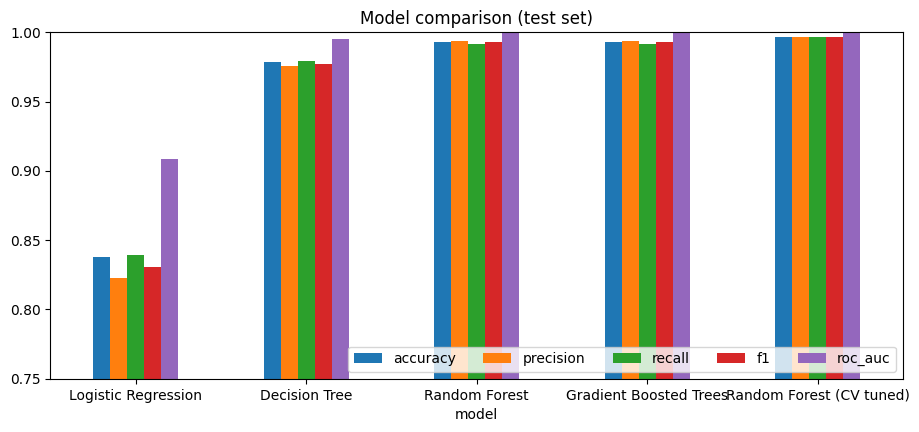

Confusion matrix - tuned Random Forest
                 Predicted: stay  Predicted: churn
Actual: stayed              6605                23
Actual: churned               20              5984


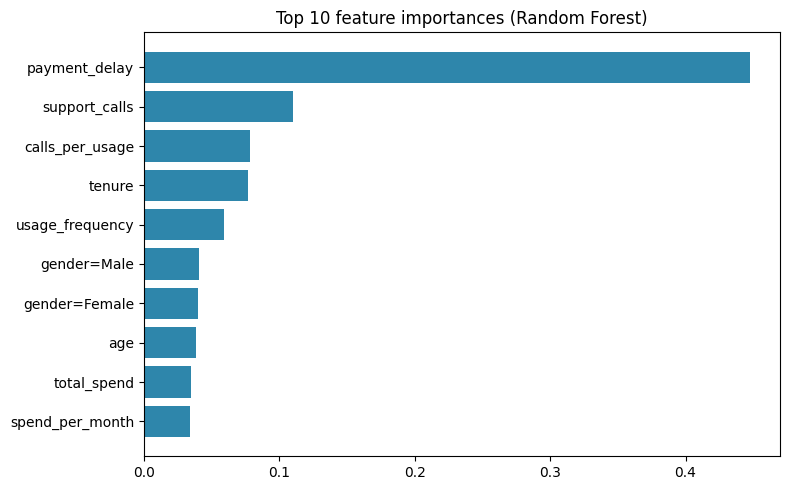

In [ ]:
comparison.set_index("model")[["accuracy", "precision", "recall", "f1", "roc_auc"]].plot(
    kind="bar", figsize=(11, 4.5), ylim=(0.75, 1.0), rot=0, title="Model comparison (test set)")
plt.legend(loc="lower right", ncol=5); plt.show()

r = comparison.iloc[-1]
print("Confusion matrix - tuned Random Forest")
print(pd.DataFrame([[r.TN, r.FP], [r.FN, r.TP]], index=["Actual: stayed", "Actual: churned"],
                   columns=["Predicted: stay", "Predicted: churn"]))

names = list(FEATURES)
for st_ in best_model.stages[:len(CATEGORICAL)]:
    names += [f"{st_.getInputCol()}={lab}" for lab in st_.labels]
imp = best_rf.featureImportances.toArray()
fi = (pd.DataFrame({"feature": names[:len(imp)], "importance": imp.round(4)})
        .sort_values("importance", ascending=False))
top = fi.head(10).iloc[::-1]
plt.figure(figsize=(8, 5)); plt.barh(top.feature, top.importance, color="#2e86ab")
plt.title("Top 10 feature importances (Random Forest)"); plt.tight_layout(); plt.show()

### 9.5 Save the model and results

In [ ]:
best_model.write().overwrite().save("churn_model")
comparison.to_csv("model_comparison.csv", index=False)
fi.to_csv("feature_importance.csv", index=False)
print("Saved: churn_model/, model_comparison.csv, feature_importance.csv")

Saved: churn_model/, model_comparison.csv, feature_importance.csv


### 9.6 Predict churn for a new customer

In [ ]:
from pyspark.ml.functions import vector_to_array

new_customer = spark.createDataFrame(
    [(1, 46.0, 30.0, 12.0, 6.0, 24.0, 540.0, 14.0, "Female", "Basic", "Monthly")],
    ["customer_id"] + NUMERIC + CATEGORICAL)
(best_model.transform(add_features(new_customer))
    .select("customer_id", "payment_delay", "support_calls", "contract_length",
            F.round(vector_to_array("probability")[1], 4).alias("churn_probability"), "prediction")
    .show())

+-----------+-------------+-------------+---------------+-----------------+----------+
|customer_id|payment_delay|support_calls|contract_length|churn_probability|prediction|
+-----------+-------------+-------------+---------------+-----------------+----------+
|          1|         24.0|          6.0|        Monthly|           0.9858|       1.0|
+-----------+-------------+-------------+---------------+-----------------+----------+



## 10. Streamlit web application
### 10.1 Write the app file
The app starts its own Spark session, loads the saved model and has 6 pages: Dashboard, Explore Data, Predict Customer, Batch Prediction, Model Performance, Spark SQL.

In [ ]:
%%writefile app.py
"""Customer Churn Analysis - Streamlit web app (PySpark backend). Written by the Colab notebook."""
import os
import warnings

warnings.filterwarnings("ignore")

import pandas as pd
import streamlit as st
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType, StringType
from pyspark.ml import PipelineModel
from pyspark.ml.functions import vector_to_array

DATA_PATH = "customer_churn.csv"
MODEL_PATH = "churn_model"
NUMERIC = ["age", "tenure", "usage_frequency", "support_calls", "payment_delay", "total_spend",
           "last_interaction"]
CATEGORICAL = ["gender", "subscription_type", "contract_length"]
RENAME = {"CustomerID": "customer_id", "Age": "age", "Gender": "gender", "Tenure": "tenure",
          "Usage Frequency": "usage_frequency", "Support Calls": "support_calls",
          "Payment Delay": "payment_delay", "Subscription Type": "subscription_type",
          "Contract Length": "contract_length", "Total Spend": "total_spend",
          "Last Interaction": "last_interaction", "Churn": "churn"}
CHURN, STAY = "#d1495b", "#2e86ab"

st.set_page_config(page_title="Churn Analysis", page_icon="📉", layout="wide")


# ---------------------------------------------------------------- Spark backend
def add_features(df):
    return (df
            .withColumn("spend_per_month", F.round(F.col("total_spend") / F.greatest(F.col("tenure"), F.lit(1)), 2))
            .withColumn("calls_per_usage", F.round(F.col("support_calls") / (F.col("usage_frequency") + 1), 3))
            .withColumn("age_group", F.when(F.col("age") < 30, "18-29").when(F.col("age") < 45, "30-44")
                        .when(F.col("age") < 60, "45-59").otherwise("60+"))
            .withColumn("tenure_group", F.when(F.col("tenure") <= 12, "0-12 m").when(F.col("tenure") <= 24, "13-24 m")
                        .when(F.col("tenure") <= 36, "25-36 m").otherwise("37+ m")))


@st.cache_resource(show_spinner="Starting Spark…")
def spark():
    s = SparkSession.builder.appName("ChurnWebApp").master("local[*]") \
        .config("spark.sql.shuffle.partitions", "8").getOrCreate()
    s.sparkContext.setLogLevel("ERROR")
    return s


@st.cache_resource(show_spinner="Loading data into Spark…")
def customers():
    df = spark().read.csv(DATA_PATH, header=True, inferSchema=True)
    for old, new in RENAME.items():
        df = df.withColumnRenamed(old, new)
    df = add_features(df.dropDuplicates(["customer_id"]).dropna()).cache()
    df.count()
    df.createOrReplaceTempView("customers")
    return df


@st.cache_resource(show_spinner="Loading the trained model…")
def model():
    return PipelineModel.load(MODEL_PATH)


@st.cache_data(show_spinner=False)
def sql(q):
    customers()
    return spark().sql(q).toPandas()


@st.cache_data(show_spinner=False)
def churn_by(col):
    return sql(f"""SELECT {col}, COUNT(*) AS Customers, ROUND(AVG(churn) * 100, 2) AS `Churn rate (%)`
                   FROM customers GROUP BY {col} ORDER BY {col}""")


def score(pdf):
    schema = StructType([StructField("customer_id", IntegerType())]
                        + [StructField(c, DoubleType()) for c in NUMERIC]
                        + [StructField(c, StringType()) for c in CATEGORICAL])
    rows = [(int(r["customer_id"]), *[float(r[c]) for c in NUMERIC], *[str(r[c]).strip() for c in CATEGORICAL])
            for r in pdf.to_dict("records")]
    out = (model().transform(add_features(spark().createDataFrame(rows, schema)))
           .withColumn("churn_probability", F.round(vector_to_array("probability")[1], 4))
           .withColumn("predicted_churn", F.col("prediction").cast("int"))
           .withColumn("risk_level", F.when(F.col("churn_probability") >= 0.7, "High")
                       .when(F.col("churn_probability") >= 0.4, "Medium").otherwise("Low")))
    return out.select("customer_id", *NUMERIC, *CATEGORICAL, "predicted_churn", "churn_probability",
                      "risk_level").toPandas()


# ---------------------------------------------------------------- sidebar
st.sidebar.title("📉 Churn Analysis")
st.sidebar.caption(f"PySpark {spark().version} · Streamlit {st.__version__}")
page = st.sidebar.radio("Pages", ["Dashboard", "Explore Data", "Predict Customer", "Batch Prediction",
                                  "Model Performance", "Spark SQL"])

# ---------------------------------------------------------------- pages
if page == "Dashboard":
    st.title("Customer Churn Dashboard")
    st.caption("Live figures computed with Spark on the full dataset.")
    k = sql("""SELECT COUNT(*) n, SUM(churn) churned, AVG(churn) rate, SUM(total_spend) revenue,
               SUM(CASE WHEN churn = 1 THEN total_spend ELSE 0 END) lost, AVG(tenure) tenure
               FROM customers""").iloc[0]
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Customers", f"{int(k.n):,}")
    c2.metric("Churned", f"{int(k.churned):,}", f"{k.rate * 100:.1f}% churn rate", delta_color="off")
    c3.metric("Revenue lost", f"₹{k.lost / 1e6:.2f} M", f"{k.lost / k.revenue * 100:.1f}% of revenue",
              delta_color="off")
    c4.metric("Average tenure", f"{k.tenure:.1f} months")
    st.divider()
    a, b = st.columns(2)
    with a:
        st.subheader("Churn vs payment delay")
        d = sql("""SELECT CASE WHEN payment_delay <= 10 THEN '0-10 days' WHEN payment_delay <= 20
                   THEN '11-20 days' ELSE '21+ days' END AS `Payment delay`,
                   ROUND(AVG(churn) * 100, 2) AS `Churn rate (%)` FROM customers GROUP BY 1 ORDER BY 1""")
        st.bar_chart(d, x="Payment delay", y="Churn rate (%)", color=CHURN, height=280)
    with b:
        st.subheader("Churn vs support calls")
        st.line_chart(churn_by("support_calls"), x="support_calls", y="Churn rate (%)", color=CHURN, height=280)
    st.subheader("Churn rate by segment")
    cols = st.columns(3)
    for col, field in zip(cols, ["contract_length", "gender", "tenure_group"]):
        col.markdown(f"**{field.replace('_', ' ').title()}**")
        col.bar_chart(churn_by(field), x=field, y="Churn rate (%)", color=STAY, height=240)
    hr = sql("""SELECT COUNT(*) n, ROUND(AVG(churn) * 100, 1) rate FROM customers
                WHERE support_calls > 5 AND payment_delay > 20""").iloc[0]
    st.info(f"**High-risk segment:** {int(hr.n):,} customers have more than 5 support calls and more than "
            f"20 days payment delay; {hr.rate}% of them churned.")

elif page == "Explore Data":
    st.title("Explore Data")
    f1, f2, f3 = st.columns(3)
    genders = f1.multiselect("Gender", ["Female", "Male"], ["Female", "Male"])
    subs = f2.multiselect("Subscription", ["Basic", "Standard", "Premium"], ["Basic", "Standard", "Premium"])
    contracts = f3.multiselect("Contract", ["Monthly", "Quarterly", "Annual"], ["Monthly", "Quarterly", "Annual"])
    ages = st.slider("Age", 18, 65, (18, 65))
    fdf = customers().filter(F.col("gender").isin(genders) & F.col("subscription_type").isin(subs)
                             & F.col("contract_length").isin(contracts) & F.col("age").between(*ages))
    s = fdf.agg(F.count("*").alias("n"), F.avg("churn").alias("r")).first()
    m1, m2 = st.columns(2)
    m1.metric("Customers in selection", f"{s['n']:,}")
    m2.metric("Churn rate in selection", f"{(s['r'] or 0) * 100:.1f}%")
    if s["n"]:
        feat = st.selectbox("Feature", NUMERIC, index=4)
        lo, hi = fdf.agg(F.min(feat), F.max(feat)).first()
        w = (hi - lo) / 20 or 1
        h = (fdf.withColumn("bin", F.least(F.floor((F.col(feat) - lo) / w), F.lit(19))).groupBy("bin")
             .agg(F.sum(1 - F.col("churn")).alias("Stayed"), F.sum("churn").alias("Churned")).orderBy("bin").toPandas())
        h[feat] = (lo + h["bin"] * w).round(1)
        st.bar_chart(h, x=feat, y=["Stayed", "Churned"], color=[STAY, CHURN], height=300)
        avg = fdf.groupBy("churn").agg(*[F.round(F.avg(c), 2).alias(c) for c in NUMERIC]).orderBy("churn").toPandas()
        avg["churn"] = avg["churn"].map({0: "Stayed", 1: "Churned"})
        st.markdown("**Average values**")
        st.dataframe(avg.set_index("churn").T, width="stretch")
        st.markdown("**Records (first 300)**")
        st.dataframe(fdf.drop("age_group", "tenure_group").limit(300).toPandas(), hide_index=True, width="stretch")

elif page == "Predict Customer":
    st.title("Predict Customer Churn")
    with st.form("f"):
        c1, c2, c3 = st.columns(3)
        age = c1.number_input("Age", 18, 100, 46)
        gender = c1.selectbox("Gender", ["Female", "Male"])
        tenure = c1.number_input("Tenure (months)", 1, 120, 30)
        usage = c2.number_input("Usage frequency", 0, 60, 12)
        calls = c2.number_input("Support calls", 0, 20, 6)
        delay = c2.number_input("Payment delay (days)", 0, 60, 24)
        last = c2.number_input("Last interaction (days ago)", 0, 60, 14)
        sub = c3.selectbox("Subscription type", ["Basic", "Standard", "Premium"])
        contract = c3.selectbox("Contract length", ["Monthly", "Quarterly", "Annual"])
        spend = c3.number_input("Total spend (₹)", 0, 5000, 540)
        go = st.form_submit_button("Predict churn", type="primary")
    if go:
        row = pd.DataFrame([dict(customer_id=0, age=age, tenure=tenure, usage_frequency=usage, support_calls=calls,
                                 payment_delay=delay, total_spend=spend, last_interaction=last, gender=gender,
                                 subscription_type=sub, contract_length=contract)])
        r = score(row).iloc[0]
        p = float(r.churn_probability)
        st.metric("Churn probability", f"{p * 100:.1f}%")
        st.progress(p, text=f"{r.risk_level} risk")
        msg = {"High": st.error, "Medium": st.warning, "Low": st.success}[r.risk_level]
        msg(f"**{r.risk_level} risk** — customer is likely to "
            f"{'**churn**' if r.predicted_churn == 1 else '**stay**'}.")
        tips = []
        if delay > 20: tips.append("Send a payment reminder and offer auto-pay.")
        if calls >= 5: tips.append("Escalate open issues to a senior support agent.")
        if contract == "Monthly": tips.append("Offer a discount to move to a quarterly or annual plan.")
        if r.risk_level != "Low" and tips:
            st.markdown("**Suggested actions**\n" + "\n".join(f"- {t}" for t in tips))

elif page == "Batch Prediction":
    st.title("Batch Prediction")
    up = st.file_uploader("Upload a CSV with the same columns as the dataset", type="csv")
    pdf = pd.read_csv(up) if up else customers().sample(fraction=0.01, seed=7).limit(500).toPandas()
    st.caption("Scoring your file." if up else "No file uploaded, so 500 sample customers are scored.")
    pdf = pdf.rename(columns=RENAME)
    need = ["customer_id"] + NUMERIC + CATEGORICAL
    miss = [c for c in need if c not in pdf.columns]
    if miss:
        st.error(f"Missing columns: {', '.join(miss)}")
        st.stop()
    pdf = pdf.dropna(subset=need)
    res = score(pdf[need])
    if "churn" in pdf.columns:
        res = res.merge(pdf[["customer_id", "churn"]], on="customer_id", how="left")
    c1, c2, c3 = st.columns(3)
    c1.metric("Customers scored", f"{len(res):,}")
    c2.metric("High risk", f"{int((res.risk_level == 'High').sum()):,}")
    if "churn" in res.columns:
        c3.metric("Accuracy vs actual", f"{(res.churn == res.predicted_churn).mean() * 100:.1f}%")
    res = res.sort_values("churn_probability", ascending=False)
    st.dataframe(res, hide_index=True, width="stretch", height=380)
    st.download_button("Download predictions (CSV)", res.to_csv(index=False), "churn_predictions.csv", "text/csv")

elif page == "Model Performance":
    st.title("Model Performance")
    mc = pd.read_csv("model_comparison.csv")
    best = mc.loc[mc.roc_auc.idxmax()]
    c1, c2, c3 = st.columns(3)
    c1.metric("Best model", best.model)
    c2.metric("Accuracy", f"{best.accuracy * 100:.2f}%")
    c3.metric("ROC-AUC", f"{best.roc_auc:.4f}")
    metric = st.selectbox("Metric", ["accuracy", "precision", "recall", "f1", "roc_auc"])
    st.bar_chart(mc, x="model", y=metric, color=STAY, height=300)
    st.dataframe(mc, hide_index=True, width="stretch")
    if os.path.exists("feature_importance.csv"):
        st.subheader("Feature importance")
        fi = pd.read_csv("feature_importance.csv").head(10)
        st.bar_chart(fi, x="feature", y="importance", color=CHURN, horizontal=True, height=330)

elif page == "Spark SQL":
    st.title("Spark SQL Console")
    st.caption("Table: customers — columns: " + ", ".join(customers().columns))
    q = st.text_area("Query", """SELECT subscription_type, contract_length, COUNT(*) AS customers,
       ROUND(AVG(churn) * 100, 2) AS churn_rate_pct
FROM customers GROUP BY subscription_type, contract_length ORDER BY churn_rate_pct DESC""", height=150)
    if st.button("Run query", type="primary"):
        if not q.strip().lower().startswith(("select", "with")):
            st.error("Only SELECT queries are allowed.")
        else:
            try:
                st.dataframe(spark().sql(q).limit(1000).toPandas(), hide_index=True, width="stretch")
            except Exception as e:
                st.error(str(e).splitlines()[0])

Writing app.py


### 10.2 Run the website and get a public link
Colab cannot open `localhost` for others, so a free Cloudflare tunnel gives the app a public `https://….trycloudflare.com` link. The link works while this notebook is running. The first page load takes about 20 seconds while Spark starts.

In [ ]:
import subprocess, time, re, os

subprocess.run("pkill -f 'streamlit run' ; pkill -f cloudflared", shell=True)
if not os.path.exists("cloudflared"):
    subprocess.run("wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/"
                   "cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared", shell=True)

subprocess.Popen("streamlit run app.py --server.port 8501 --server.headless true > streamlit.log 2>&1", shell=True)
time.sleep(5)
subprocess.Popen("./cloudflared tunnel --url http://localhost:8501 --no-autoupdate > tunnel.log 2>&1", shell=True)

url = None
for _ in range(30):
    time.sleep(2)
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("tunnel.log").read())
    if m:
        url = m.group(0); break
print("Open the website:", url or "not ready yet - run this cell again")

Open the website: https://raised-produce-condos-inc.trycloudflare.com


## 11. Conclusion
- Overall churn rate is about **47%** of 64,374 customers.
- **Payment delay** is the strongest driver of churn, followed by **support calls**: customers 21+ days late
  churn about 77% of the time, and churn more than doubles at 5 or more support calls.
- **Monthly contracts** churn more than quarterly or annual ones; subscription type barely matters.
- Tree-based Spark MLlib models reach above **99% accuracy**; the tuned Random Forest performs best.
  Scores are this high because the dataset is highly separable, so real-world data would score lower.
- The trained Spark pipeline is served through a **Streamlit** web app for single and batch predictions.